# 15. Alert lead time vs. labeled stress periods (Week 6)

**Owner:** Rishi. Task from the plan: *measure alert lead time vs. labeled stress periods.*

This is the core comparison for the research question: do our signals warn **earlier** than the standard indicators (VIX and the St. Louis Fed Financial Stress Index, STLFSI4)?

**Signals compared**
| Signal | Rule |
|---|---|
| Network anomaly (combined) | notebook 13 alert: z-score or stress-direction Isolation Forest |
| Network z-score only | any network metric z >= 2 |
| Model alert | "+ z-scores + IF" model from notebook 14 (top 10% probability) |
| Baseline model alert | VIX + past volatility model from notebook 14 |
| VIX > 25 | common rule of thumb for an elevated VIX |
| VIX z-score | VIX at least 2 standard deviations above its previous year |
| STLFSI4 > 0 / > 1 | above-average stress / clearly elevated; **lagged 4 trading days** for publication |

**Scoring** (`src/alerts.py`): for each episode, the first alert in the 60 trading days before its start (not reaching back into the previous episode) gives the lead time. First alerts in the 10 days after the start count as late. Alert days are grouped into events; an event that is not followed by an episode start within 60 days, and does not start inside an episode, is a false alarm. Both start dates are reported (`start` and `start_trailing`).

**STLFSI4 lag:** the panel carries STLFSI4 on its observation date (the Friday that ends each week). FRED's update stamps show it is published the following Wednesday or Thursday (for example, the week ending 2026-10-30 was updated 2026-11-04, and the week ending 2026-10-16 on 2026-10-22). It is therefore shifted 4 trading days, so each reading is used from the Thursday after its week. **Second caveat:** FRED serves the current, revised version of the whole index history, not the values that were available in real time, which may flatter STLFSI4 slightly.

In [1]:
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Works from the repo root or from notebooks/. RGBFS_DATA_ROOT is only for test runs on fake data.
CODE_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "anomaly.py").exists())
DATA_ROOT = Path(os.environ.get("RGBFS_DATA_ROOT", CODE_ROOT))
sys.path.insert(0, str(CODE_ROOT))

from src import anomaly as an
from src import alerts as al

PROC = DATA_ROOT / "data" / "processed"
FEATURES = PROC / "features"
EPISODES_CSV = DATA_ROOT / "docs" / "stress_periods.csv"
OUT = DATA_ROOT / "notebooks" / "outputs" / "rishi_week6"
OUT.mkdir(parents=True, exist_ok=True)
print("Code:", CODE_ROOT)
print("Data:", DATA_ROOT)

Code: /home/claude/rgbfs
Data: /home/claude/rgbfs


In [2]:
def shade_episodes(ax, episodes, color="tab:red", alpha=0.12):
    for _, ep in episodes.iterrows():
        ax.axvspan(ep.start, ep.end, color=color, alpha=alpha, lw=0)

## 1. Build every signal on the trading-day calendar

In [3]:
panel = pd.read_parquet(PROC / "daily_panel.parquet").sort_index()
panel.index = pd.to_datetime(panel.index)
cal = panel.index
episodes = al.load_episodes(EPISODES_CSV)
anom = pd.read_parquet(FEATURES / "anomaly_network_daily.parquet").reindex(cal)

vix = panel["VIXCLS"].ffill(limit=3)
vix_z = an.trailing_zscores(vix.to_frame("vix"), lookback=252, min_periods=126)["vix"]
stlfsi = panel["STLFSI4"].shift(4)
start_common = anom.alert.first_valid_index()   # compare all signals over the same period

def from_common(s):
    s = s.astype(float).where(s.notna())
    return s.where(s.index >= start_common)

signals = {
    "Network anomaly (combined)": anom.alert,
    "Network z-score only": anom.z_flag,
    "VIX > 25": (vix > 25).astype(float).where(vix.notna()),
    "VIX z >= 2": (vix_z >= 2).astype(float).where(vix_z.notna()),
    "STLFSI4 > 0 (lagged)": (stlfsi > 0).astype(float).where(stlfsi.notna()),
    "STLFSI4 > 1 (lagged)": (stlfsi > 1).astype(float).where(stlfsi.notna()),
}
model_path = DATA_ROOT / "notebooks" / "outputs" / "rishi_week5" / "model_alerts_daily.csv"
if model_path.exists():
    m = pd.read_csv(model_path, index_col="date", parse_dates=True).reindex(cal)
    test = (cal >= m.index[m["baseline|alert"].notna()].min()) & (cal <= m.index[m["baseline|alert"].notna()].max())
    for label, col in [("Model alert (+ z + IF)", "+ z-scores + IF|alert"), ("Baseline model alert (VIX + vol)", "baseline|alert")]:
        signals[label] = m[col].where(~(test & m[col].isna()), 0.0).where(test)
else:
    print("Run notebook 14 first to include the model alerts")
signals = {k: from_common(v) for k, v in signals.items()}
print("Common start:", start_common.date())

Common start: 2005-10-10


## 2. Summary for each signal

In [4]:
summary = pd.DataFrame([al.summarize_signal(name, s, episodes, start_col=col)
                        for col in ["start", "start_trailing"] for name, s in signals.items()])
cols = ["signal", "start_col", "episodes_scored", "warned_early", "late", "missed", "median_lead_days",
        "false_alarms_per_year", "day_precision", "day_recall", "day_false_alarm_rate"]
summary[cols].round(3)

,signal,start_col,episodes_scored,warned_early,late,missed,median_lead_days,false_alarms_per_year,day_precision,day_recall,day_false_alarm_rate
0,Network anomaly (combined),start,13,8,4,1,27.5,0.570,0.113,0.238,0.111
1,Network z-score only,start,13,8,4,1,27.5,0.570,0.113,0.238,0.111
2,VIX > 25,start,13,8,5,0,39.5,1.283,0.106,0.138,0.070
3,VIX z >= 2,start,13,7,5,1,29.0,1.188,0.169,0.112,0.033
4,STLFSI4 > 0 (lagged),start,13,8,3,2,41.5,1.140,0.048,0.212,0.248
5,STLFSI4 > 1 (lagged),start,13,2,0,11,57.5,0.238,0.145,0.135,0.047
6,Model alert (+ z + IF),start,9,5,0,4,36.0,1.974,0.051,0.178,0.177
7,Baseline model alert (VIX + vol),start,9,5,0,4,28.0,1.019,0.140,0.183,0.060
8,Network anomaly (combined),start_trailing,13,12,0,1,24.5,0.665,0.146,0.335,0.113
9,Network z-score only,start_trailing,13,12,0,1,24.5,0.665,0.146,0.335,0.113


## 3. Lead time by episode

Positive = warned that many trading days before the start. Negative = late. Blank = missed or no data for that signal yet. `*` = the signal was already on when the 60-day window opened, so the lead is capped by the window rather than a clean early warning.

In [5]:
def lead_table(start_col):
    cols = {}
    for name, s in signals.items():
        lt = al.lead_times(s, episodes, start_col=start_col)
        cols[name] = [("" if not r.has_data else ("missed" if pd.isna(r.lead_days) else f"{r.lead_days:.0f}{'*' if r.already_on else ''}"))
                      for r in lt.itertuples()]
    t = pd.DataFrame(cols)
    t.insert(0, "start", al.lead_times(next(iter(signals.values())), episodes, start_col=start_col)["start"].dt.date)
    t.insert(0, "episode", episodes["name"])
    return t

leads_start = lead_table("start")
leads_trailing = lead_table("start_trailing")
leads_start

,episode,start,Network anomaly (combined),Network z-score only,VIX > 25,VIX z >= 2,STLFSI4 > 0 (lagged),STLFSI4 > 1 (lagged),Model alert (+ z + IF),Baseline model alert (VIX + vol)
0,Aug 2007 credit and quant-fund stress,2007-08-03,6,6,0,27,-4,missed,,
1,Bear Stearns,2008-03-04,missed,missed,38,29,60*,60*,,
2,Global financial crisis (Lehman),2008-08-29,22,22,41,-10,60*,55,,
3,Flash crash and first euro-area debt stress,2010-04-26,-8,-8,55,-8,55,missed,,
4,"U.S. debt ceiling, S&P downgrade and euro-area...",2011-07-25,7,7,-4,-8,2,missed,60*,missed
5,China devaluation selloff,2015-08-12,-9,-9,-7,-7,23,missed,16,missed
6,Feb 2018 volatility spike,2018-02-01,-1,-1,-2,3,-10,missed,60*,missed
7,Q4 2018 selloff,2018-12-11,30,30,32,42,7,missed,27,22
8,COVID-19 crash,2020-02-14,-9,-9,-5,-5,missed,missed,missed,missed
9,Russia's invasion of Ukraine,2022-02-23,51,51,60,60,-6,missed,missed,43


In [6]:
leads_trailing

,episode,start,Network anomaly (combined),Network z-score only,VIX > 25,VIX z >= 2,STLFSI4 > 0 (lagged),STLFSI4 > 1 (lagged),Model alert (+ z + IF),Baseline model alert (VIX + vol)
0,Aug 2007 credit and quant-fund stress,2007-08-17,16,16,10,37,6,-4,,
1,Bear Stearns,2008-03-18,missed,missed,48,39,60*,60*,,
2,Global financial crisis (Lehman),2008-09-15,32,32,51,0,60*,60*,,
3,Flash crash and first euro-area debt stress,2010-05-10,2,2,2,2,55,missed,,
4,"U.S. debt ceiling, S&P downgrade and euro-area...",2011-08-08,17,17,6,2,12,-8,60*,missed
5,China devaluation selloff,2015-08-26,1,1,3,3,33,missed,26,missed
6,Feb 2018 volatility spike,2018-02-14,8,8,7,12,-1,missed,32,-8
7,Q4 2018 selloff,2018-12-26,40,40,42,52,17,missed,37,32
8,COVID-19 crash,2020-03-02,1,1,5,5,-3,-8,missed,missed
9,Russia's invasion of Ukraine,2022-03-09,60*,60*,33,32,4,missed,missed,53


## 4. Network anomaly vs. VIX, head to head

For each episode both signals scored: how many trading days earlier (positive) or later (negative) the network anomaly fired than VIX z >= 2 and than VIX > 25. A missed signal is treated as firing at the end of the window, so a miss always loses.

In [7]:
def first_day_lead(s, col):
    lt = al.lead_times(s, episodes, start_col=col)
    return lt.lead_days.where(lt.has_data).fillna(-al.LATE - 1).where(lt.has_data)

h2h = pd.DataFrame({"episode": episodes["name"]})
for col in ["start", "start_trailing"]:
    net = first_day_lead(signals["Network anomaly (combined)"], col)
    for v in ["VIX z >= 2", "VIX > 25"]:
        h2h[f"vs {v} ({col})"] = net - first_day_lead(signals[v], col)
h2h

,episode,vs VIX z >= 2 (start),vs VIX > 25 (start),vs VIX z >= 2 (start_trailing),vs VIX > 25 (start_trailing)
0,Aug 2007 credit and quant-fund stress,-21.0,6.0,-21.0,6.0
1,Bear Stearns,-40.0,-49.0,-50.0,-59.0
2,Global financial crisis (Lehman),32.0,-19.0,32.0,-19.0
3,Flash crash and first euro-area debt stress,0.0,-63.0,0.0,0.0
4,"U.S. debt ceiling, S&P downgrade and euro-area...",15.0,11.0,15.0,11.0
5,China devaluation selloff,-2.0,-2.0,-2.0,-2.0
6,Feb 2018 volatility spike,-4.0,1.0,-4.0,1.0
7,Q4 2018 selloff,-12.0,-2.0,-12.0,-2.0
8,COVID-19 crash,-4.0,-4.0,-4.0,-4.0
9,Russia's invasion of Ukraine,-9.0,-9.0,28.0,27.0


## 5. Timeline

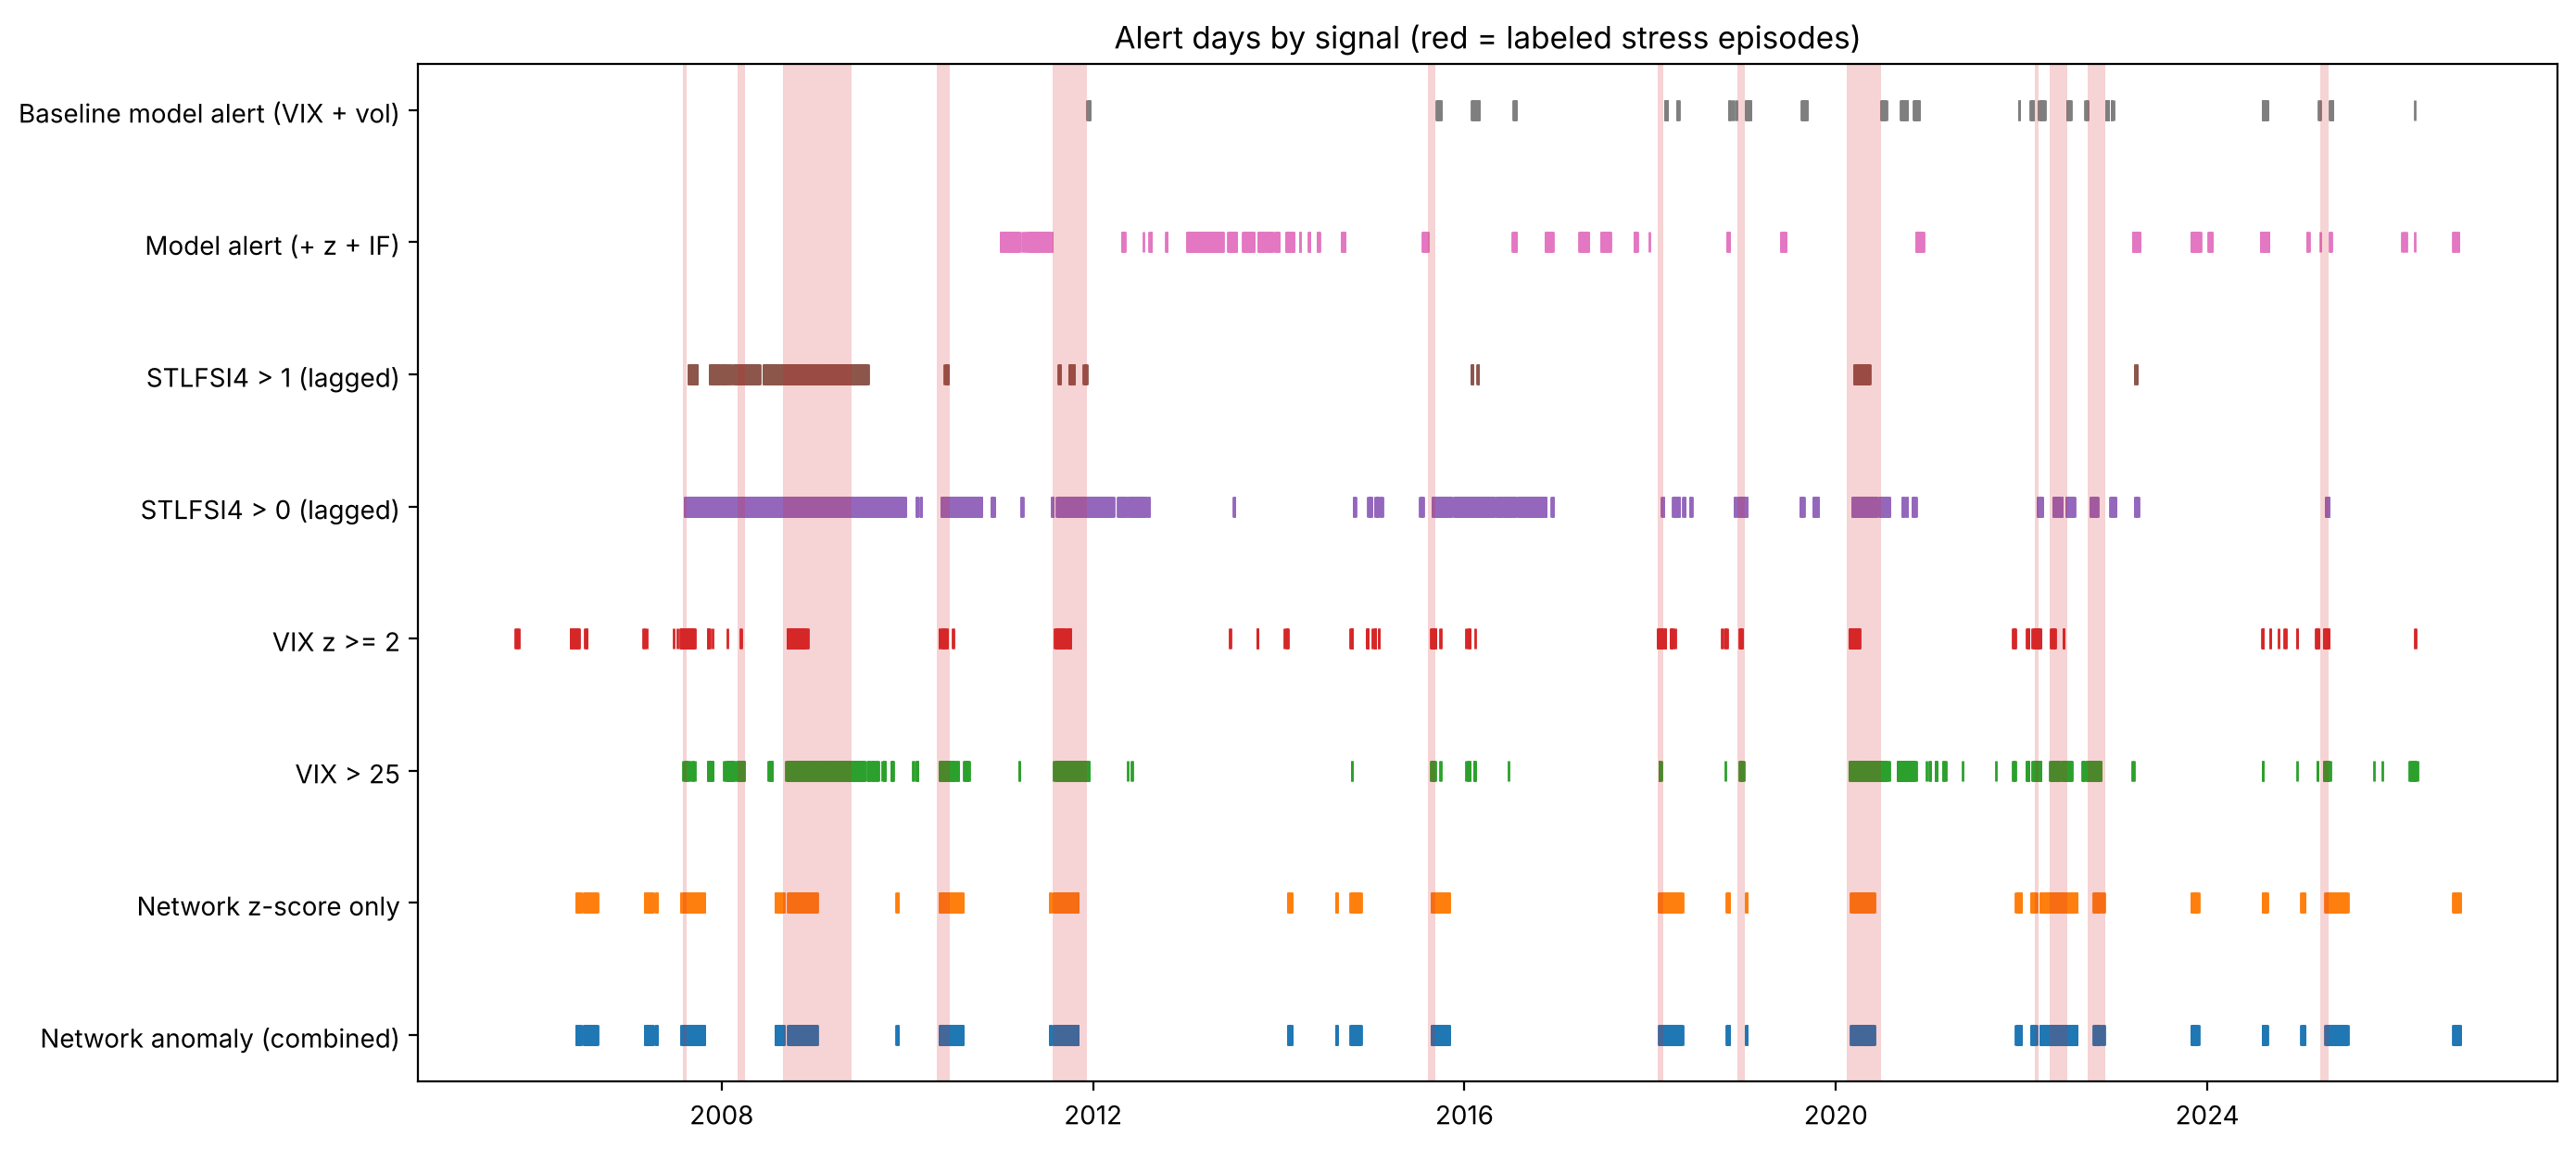

In [8]:
fig, ax = plt.subplots(figsize=(14, 0.6 * len(signals) + 1.5))
for i, (name, s) in enumerate(signals.items()):
    on = s.index[s.eq(1)]
    ax.scatter(on, np.full(len(on), i), marker="|", s=60, lw=1)
ax.set_yticks(range(len(signals)), list(signals))
shade_episodes(ax, episodes, alpha=0.2)
ax.set_title("Alert days by signal (red = labeled stress episodes)")
plt.tight_layout(); plt.savefig(OUT / "alert_timeline.png", dpi=120); plt.show()

## 6. Save outputs

The dashboard's data/alerts panel reads these files.

In [9]:
summary.to_csv(OUT / "signal_summary.csv", index=False)
leads_start.to_csv(OUT / "lead_times_by_episode_start.csv", index=False)
leads_trailing.to_csv(OUT / "lead_times_by_episode_start_trailing.csv", index=False)
h2h.to_csv(OUT / "network_vs_vix.csv", index=False)
pd.DataFrame(signals).rename_axis("date").to_csv(OUT / "signals_daily.csv")
events = pd.concat([al.score_events(s, episodes).assign(signal=name) for name, s in signals.items()], ignore_index=True)
events.to_csv(OUT / "alert_events.csv", index=False)
print("Saved to", OUT)

Saved to /home/claude/rgbfs/notebooks/outputs/rishi_week6


## 7. Findings (real data; rerun 2026-11-21 after the absorption fix; STLFSI4 lagged 4 trading days)

**Answer for this component: partly.** As a simple alert rule, the network anomaly signal matches VIX > 25 on how many episodes it warns early, with fewer false alarms. But when both fire it is usually *later* than VIX, and it does not improve a VIX-based model (notebook 14).

Using the `start` dates (13 episodes, same period for every signal):

| Signal | Early | Late | Missed | Median lead (days) | False alarms per year | Days on alert |
|---|---|---|---|---|---|---|
| Network anomaly | 8 | 4 | 1 | 27.5 | 0.57 | 11.8% |
| VIX > 25 | 8 | 5 | 0 | 39.5 | 1.28 | 7.3% |
| VIX z ≥ 2 | 7 | 5 | 1 | 29.0 | 1.19 | 3.7% |
| STLFSI4 > 0 (lagged) | 8 | 3 | 2 | 41.5 | 1.14 | 24.6% |
| STLFSI4 > 1 (lagged) | 2 | 0 | 11 | 57.5 | 0.24 | 5.2% |

**Head to head (Section 4, `start`):**
* Against VIX z ≥ 2, the network signal was earlier in 3 episodes (Lehman by 32 days, 2011 by 15, 2022 second leg, which VIX z missed), tied in 1 and later in 9.
* Against VIX > 25, it was earlier in 4 (Aug 2007, 2011, Feb 2018 by one day, 2025 tariffs by 43 days), tied in 1 and later in 8.

**Care with "early" warnings on both sides:**
* VIX > 25 fires 38 days before Bear Stearns and 41 days before Lehman because VIX was still high from the previous episodes; a level rule gets credit for stress that never ended.
* The network signal's 2022 second-leg warning was still on from the first leg.

**Consistency with the EDAs:** the 2011 EDA found average correlation crossing a fixed level about two weeks before VIX; this test agrees for 2011 (network alert 7 days before the start, VIX rules late). The 2020 and 2022 EDAs found no lead, and this test agrees for COVID (network late by 9 days).

**First run (2026-11-18) for comparison:** with the stuck absorption ratio the network alert was 5 early, 4 late, 4 missed, at 1.14 false alarms per year. See notebook 13, Section 6.